In [30]:
1250080036 % 15

1

In [31]:
%pip install pyvi


Note: you may need to restart the kernel to use updated packages.


In [32]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [33]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd
from os import listdir
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, f1_score, recall_score 
from sklearn.model_selection import GridSearchCV, train_test_split

# Han digit

In [34]:
img = cv2.imread('./alpha2/a/a.001.png', cv2.IMREAD_GRAYSCALE)
img = cv2.resize(img , ( 64, 64))
img.shape

(64, 64)

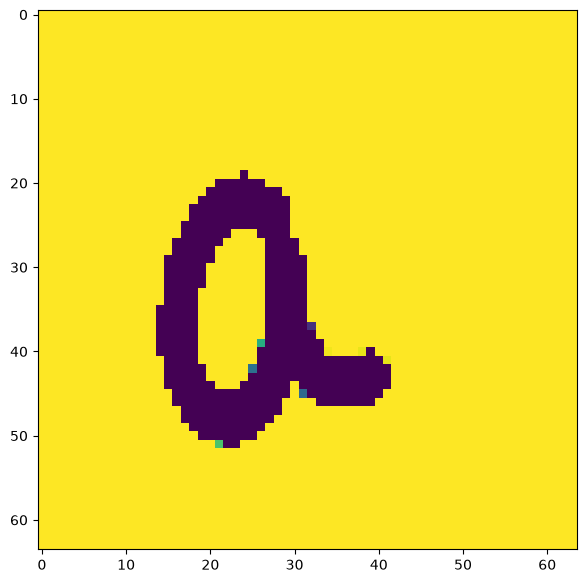

In [35]:
plt.imshow(img)
plt.show()

In [56]:
X = []
y = []
for num in listdir('./alpha2'):
    names = listdir(f'./alpha2/{num}')
    y +=   len(names) * [num]
    for name in names:
        #matrix
        img = cv2.imread(f'./alpha2/{num}/{name}', cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img , ( 64, 64))
        # MISS
        #matrix => vector 1d
        X.append(img.flatten())

X = np.array(X)
y = np.array(y)

In [57]:
X.shape, y.shape

((1144, 4096), (1144,))

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn.score(X_train, y_train), knn.score(X_test, y_test)

(0.6212121212121212, 0.3146853146853147)

In [59]:
grid = GridSearchCV(rf, param_grid={
    'max_depth': [5, 10, 15, 50, 100, 200],
})
grid.fit(X_train, y_train)
grid.best_score_, grid.best_params_

(np.float64(0.3425812593499252), {'max_depth': 50})

In [60]:
rf = RandomForestClassifier(max_depth=50)
rf.fit(X_train, y_train)
rf.score(X_train, y_train), rf.score(X_test, y_test)

(1.0, 0.4160839160839161)

In [61]:
knn = grid.best_estimator_
knn.score(X_train, y_train), knn.score(X_test, y_test)

(1.0, 0.34265734265734266)

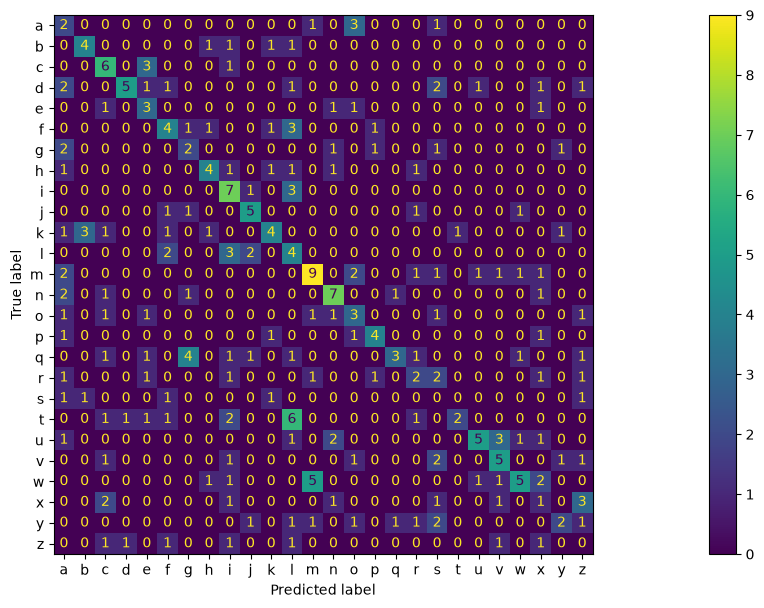

In [62]:
ConfusionMatrixDisplay.from_estimator(knn, X_test, y_test)
plt.show()

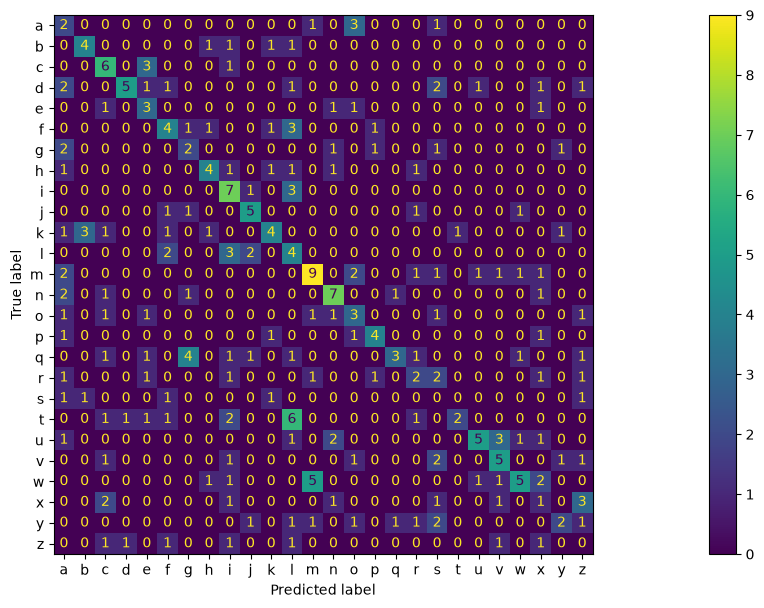

In [63]:
ConfusionMatrixDisplay.from_estimator(knn, X_test, y_test)
plt.show()

In [64]:
y_test_pred = knn.predict(X_test)
y_test_pred.shape

(286,)

In [65]:
print('Precision score', precision_score(y_test, y_test_pred, average='macro'))
print('Recall score', recall_score(y_test, y_test_pred, average='macro'))
print('F1 score', f1_score(y_test, y_test_pred, average='macro'))

Precision score 0.3812743451490255
Recall score 0.3353818555488596
F1 score 0.33333304620832965


In [66]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
dt.score(X_train, y_train), dt.score(X_test, y_test)

(1.0, 0.21328671328671328)

In [67]:
grid = GridSearchCV(dt, param_grid={
    'max_depth': [10 , 20 ,30 ,None]
})
grid.fit(X_train, y_train)
grid.best_score_, grid.best_params_

(np.float64(0.18529851761185911), {'max_depth': 30})

In [68]:
dt = DecisionTreeClassifier(max_depth=30)
dt.fit(X_train, y_train)
dt.score(X_train, y_train), dt.score(X_test, y_test)

(1.0, 0.23426573426573427)

In [69]:
dt = grid.best_estimator_
dt.score(X_train, y_train), dt.score(X_test, y_test)

(1.0, 0.23426573426573427)

In [70]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
rf.score(X_train, y_train), rf.score(X_test, y_test)

(1.0, 0.4020979020979021)

In [71]:
grid = GridSearchCV(rf, param_grid={
    'n_estimators': [100 , 300 ,500],
    'max_depth': [20 , 30 ,None]
})
grid.fit(X_train, y_train)
grid.best_score_, grid.best_params_

(np.float64(0.44284645722834215), {'max_depth': 20, 'n_estimators': 500})

In [72]:
rf = RandomForestClassifier(30)
rf.fit(X_train, y_train)
rf.score(X_train, y_train), rf.score(X_test, y_test)

(1.0, 0.4020979020979021)

In [73]:
rf = grid.best_estimator_
rf.score(X_train, y_train), rf.score(X_test, y_test)

(1.0, 0.4370629370629371)

In [74]:
validation = []
models = {
    'KNN': knn,
    'Decision Tre': dt,
    'Random Forest': rf
}
for k in models:
    y_test_pred = models[k].predict(X_test)
    validation.append({
        'Model': k,
        'Score': models[k].score(X_test, y_test),
        'Precision': precision_score(y_test, y_test_pred, average='macro'),
        'Recal': recall_score(y_test, y_test_pred, average='macro'),
        'F1-score': f1_score(y_test, y_test_pred, average='macro'),
    })
pd.DataFrame(validation)

,Model,Score,Precision,Recal,F1-score
0,KNN,0.342657,0.381274,0.335382,0.333333
1,Decision Tre,0.234266,0.227579,0.223035,0.218182
2,Random Forest,0.437063,0.450328,0.430726,0.423760


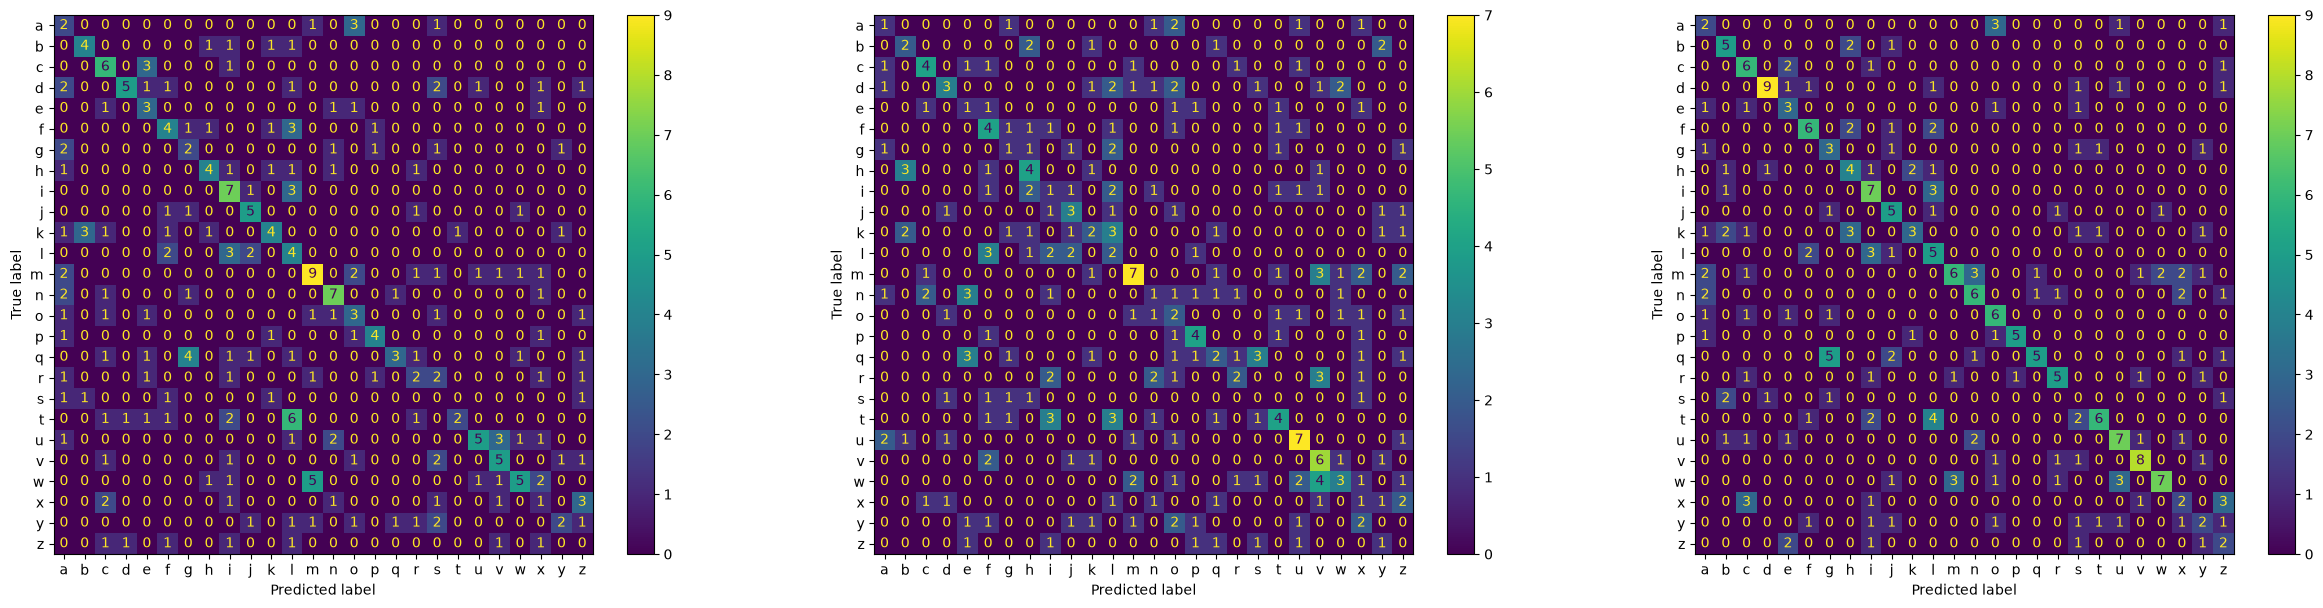

In [75]:
plt.rcParams['figure.figsize'] = (30,7)
fig , axes = plt.subplots (ncols=3)
for i , k in enumerate(models):
    ConfusionMatrixDisplay.from_estimator(models[k],X_test,y_test, ax=axes[i])
plt.show() 